# Reefugia: validating DHW against NOAA Coral Reef Watch
Compares reefugia's daily DHW for one region and year with NOAA CRW's 5 km DHW
product, using two measures.

- A **difference map** of peak DHW per pixel (reefugia − NOAA)
- **Correlations**, spatial (peak DHW across pixels) and in time (regional mean DHW per day)

Some systematic difference is expected, because the inputs differ. SST comes from
C3S here and CoralTemp at NOAA, and the MMM comes from 1991–2020 here but from
NOAA's older, cooler 1985–1990 + 1993 baseline. A warmer MMM gives smaller
HotSpots, so reefugia should come out lower. A high correlation with a steady
offset means the method is right and the remaining gap comes from the inputs.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from reefugia import fetch, detect, validate, visualise, trend
from reefugia.constants import KELVIN_TO_CELSIUS

REGION = "red_sea"
YEAR   = 2023
START, END = f"{YEAR}-01-01", f"{YEAR}-12-31"
PLACE  = visualise.pretty_region(REGION)

/Users/dtraykova/Documents/reefugia/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. reefugia DHW (from the zarr cache if it exists)

In [2]:
sst = fetch.fetch_data(REGION, START, END)["analysed_sst"]
ocean_mask = ~sst.isel(time=0).isnull().compute()
dhw = detect.load_or_compute_dhw(sst, REGION, START, END)

INFO - 2026-11-10T10:38:09Z - Selected dataset version: "202506"
INFO - 2026-11-10T10:38:09Z - Selected dataset part: "default"


## 2. NOAA CRW DHW for the same year
Downloaded from NOAA's ERDDAP server once and cached in `data/`, so reruns don't
contact NOAA again.

In [3]:
crw = trend.load_or_fetch_crw_daily(REGION, START, END)
crw

<xarray.DataArray 'CRW_DHW' (time: 365, latitude: 361, longitude: 232)> Size: 245MB
dask.array<open_dataset-CRW_DHW, shape=(365, 361, 232), dtype=float64, chunksize=(46, 91, 58), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 3kB 2023-01-01T12:00:00 ... 2023-12-31T1...
  * latitude   (latitude) float32 1kB 30.02 29.98 29.92 ... 12.12 12.07 12.02
  * longitude  (longitude) float32 928B 31.98 32.03 32.08 ... 43.42 43.47 43.53
Attributes:
    colorBarMaximum:        16.0
    colorBarMinimum:        0.0
    coverage_content_type:  physicalMeasurement
    ioos_category:          Temperature
    long_name:              degree heating week
    units:                  Celsius weeks
    valid_max:              100.0
    valid_min:              0.0

## 3. Compare

In [4]:
result = validate.compare_dhw(dhw, crw, ocean_mask)

print(f"Pixels compared:        {result['n_pixels']} over {result['n_days']} days")
print(f"Spatial r (peak DHW):   {result['r_spatial']:.2f}")
print(f"Time r (regional mean): {result['r_timeseries']:.2f}")
print(f"Mean peak DHW:          {result['mean_peak']:.1f} (reefugia) vs {result['mean_peak_reference']:.1f} (NOAA)")
print(f"Mean bias:              {result['mean_bias']:+.1f} °C-weeks")
print(f"RMSE:                   {result['rmse']:.1f} °C-weeks")

Pixels compared:        16382 over 365 days
Spatial r (peak DHW):   0.65
Time r (regional mean): 1.00
Mean peak DHW:          9.5 (reefugia) vs 12.6 (NOAA)
Mean bias:              -3.1 °C-weeks
RMSE:                   4.1 °C-weeks


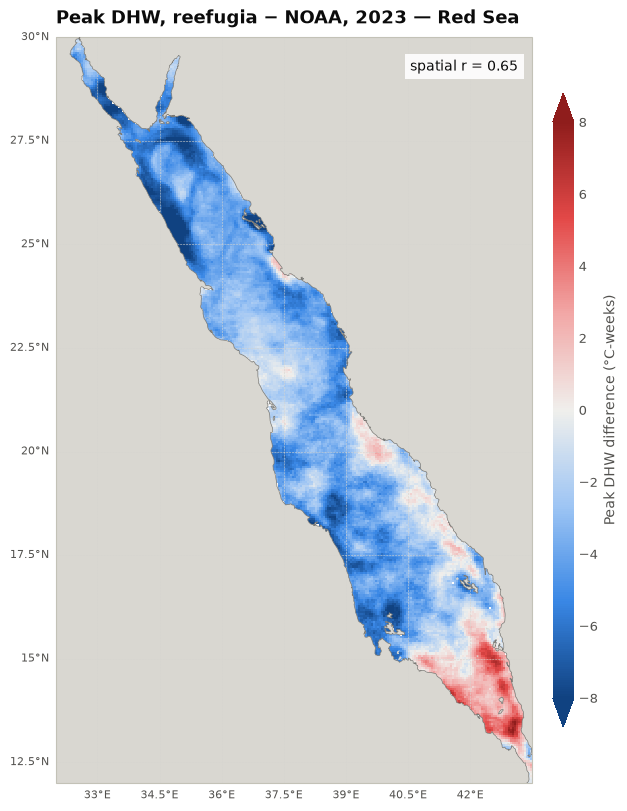

In [5]:
fig = visualise.plot_dhw_difference(
    result["diff"], result["r_spatial"],
    title=f"Peak DHW, reefugia − NOAA, {YEAR} — {PLACE}",
)
os.makedirs("../../outputs", exist_ok=True)
fig.savefig(f"../../outputs/dhw_vs_crw_{REGION}_{YEAR}.png", dpi=200, bbox_inches="tight")
plt.show()

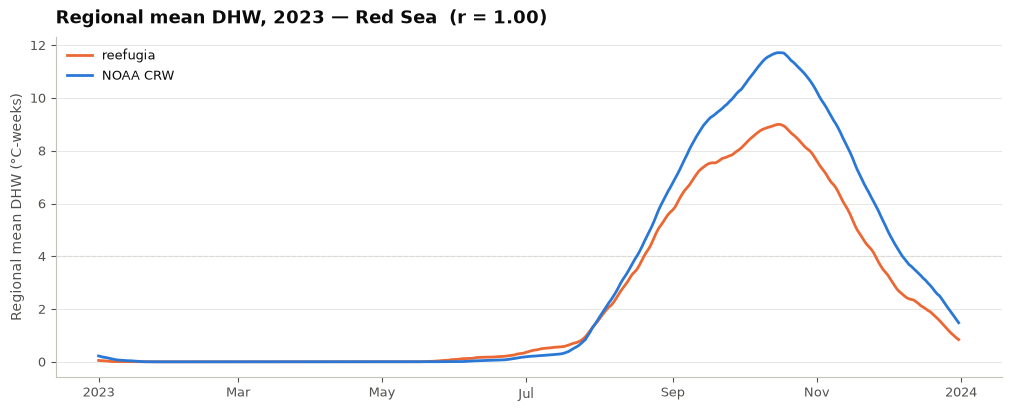

In [6]:
with plt.rc_context(visualise._STYLE):
    fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
    result["timeseries"].plot(ax=ax, color=visualise.ORANGE, linewidth=2, label="reefugia")
    result["timeseries_reference"].plot(ax=ax, color=visualise.BLUE, linewidth=2, label="NOAA CRW")
    ax.axhline(4, color="#b5b4ae", linewidth=0.8, linestyle="--", zorder=0)
    ax.set_xlabel("")
    ax.set_ylabel("Regional mean DHW (°C-weeks)")
    ax.yaxis.grid(True)
    ax.set_title(f"Regional mean DHW, {YEAR} — {PLACE}  (r = {result['r_timeseries']:.2f})")
    ax.legend(loc="upper left")
plt.show()

## 4. Where does the gap come from?
The timing matches NOAA almost perfectly, but the magnitude is lower. Two inputs
differ, the **MMM** (1991–2020 here vs NOAA's older baseline) and the **SST
product** (C3S vs CoralTemp). They can be separated, because NOAA's HotSpot is
SST − MMM, so NOAA's MMM can be recovered from its SST and HotSpot.

In [7]:
# SST from October of the previous year, so section 5 has the 12 weeks before 1 January
lead_start = (pd.Timestamp(START) - pd.Timedelta(days=83)).strftime("%Y-%m-%d")
crw_sst_lead = trend.load_or_fetch_crw_daily(REGION, lead_start, END, "CRW_SST")
crw_sst = crw_sst_lead.sel(time=slice(START, None))
crw_hotspot = trend.load_or_fetch_crw_daily(REGION, START, END, "CRW_HOTSPOT")

mmm_noaa = validate.to_grid(validate.mmm_from_crw(crw_sst, crw_hotspot), dhw)  # °C
mmm_ours = detect.load_or_compute_climatology(REGION)["mmm"].compute() + KELVIN_TO_CELSIUS
mmm_diff = (mmm_ours - mmm_noaa).where(ocean_mask)

sst_ours = sst.mean(dim="time").compute() + KELVIN_TO_CELSIUS
sst_noaa = validate.to_grid(crw_sst.mean(dim="time"), dhw)
sst_diff = (sst_ours - sst_noaa).where(ocean_mask)

print(f"MMM, reefugia − NOAA:          mean {float(mmm_diff.mean()):+.2f} °C, "
      f"range {float(mmm_diff.quantile(0.05)):+.2f} to {float(mmm_diff.quantile(0.95)):+.2f} °C (5–95%)")
print(f"Annual mean SST, C3S − CRW:    mean {float(sst_diff.mean()):+.2f} °C, "
      f"range {float(sst_diff.quantile(0.05)):+.2f} to {float(sst_diff.quantile(0.95)):+.2f} °C (5–95%)")

MMM, reefugia − NOAA:          mean +0.56 °C, range +0.38 to +0.82 °C (5–95%)
Annual mean SST, C3S − CRW:    mean +0.22 °C, range +0.06 to +0.38 °C (5–95%)


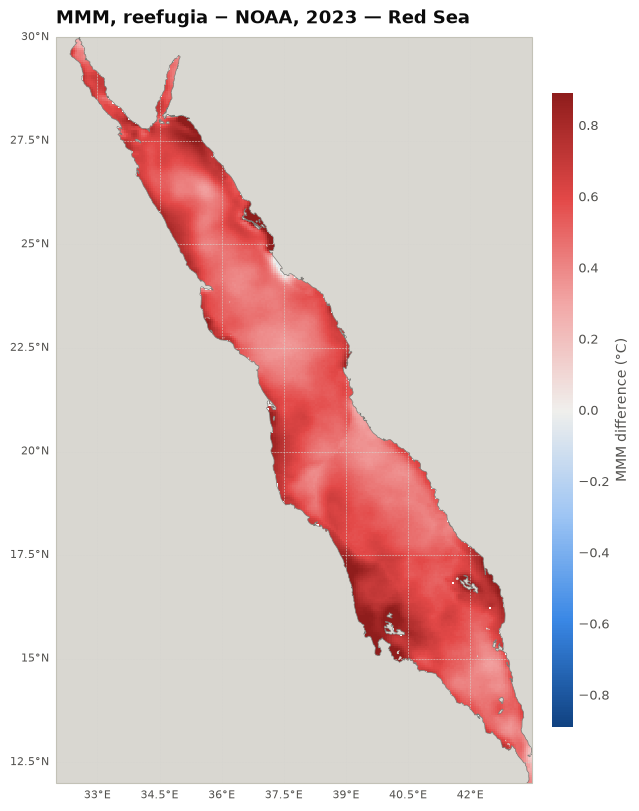

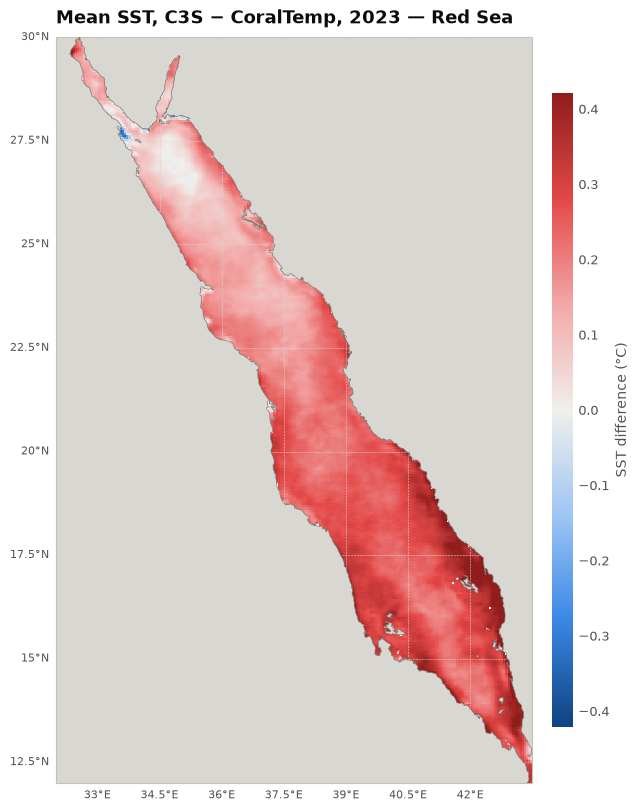

In [8]:
for diff, label, name in [(mmm_diff, "MMM difference (°C)", "MMM, reefugia − NOAA"),
                          (sst_diff, "SST difference (°C)", "Mean SST, C3S − CoralTemp")]:
    lim = float(abs(diff).quantile(0.98))
    visualise.plot_map(diff, label, title=f"{name}, {YEAR} — {PLACE}",
                       cmap=visualise.DIVERGING_CMAP, vmin=-lim, vmax=lim)
    plt.show()

### reefugia DHW with NOAA's MMM
Recomputing reefugia's DHW with NOAA's MMM leaves the SST product as the only
difference. If the bias mostly disappears, the method is right and the gap was
the baseline.

In [9]:
dhw_noaa_mmm = detect.compute_dhw(sst, REGION, mmm=mmm_noaa - KELVIN_TO_CELSIUS)
result_noaa_mmm = validate.compare_dhw(dhw_noaa_mmm, crw, ocean_mask)

keys = ["r_spatial", "r_timeseries", "mean_peak", "mean_peak_reference", "mean_bias", "rmse"]
pd.DataFrame({"reefugia MMM (1991–2020)": [result[k] for k in keys],
              "NOAA MMM": [result_noaa_mmm[k] for k in keys]}, index=keys).round(2)

INFO - 2026-11-10T10:41:24Z - Selected dataset version: "202506"
INFO - 2026-11-10T10:41:24Z - Selected dataset part: "default"


,reefugia MMM (1991–2020),NOAA MMM
r_spatial,0.65,0.79
r_timeseries,1.00,0.99
mean_peak,9.54,16.91
mean_peak_reference,12.59,12.59
mean_bias,-3.06,4.31
rmse,4.12,5.35


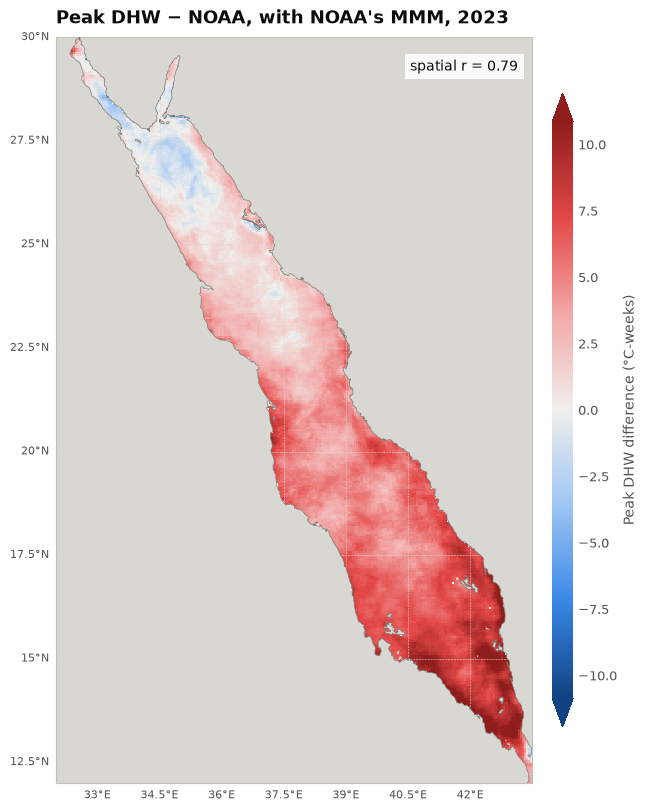

In [10]:
fig = visualise.plot_dhw_difference(
    result_noaa_mmm["diff"], result_noaa_mmm["r_spatial"],
    title=f"Peak DHW − NOAA, with NOAA's MMM, {YEAR}",
)
plt.show()

## 5. Same inputs as NOAA
The final check of the method. reefugia's DHW code runs on NOAA's own SST
(CoralTemp) with NOAA's MMM, so every input matches NOAA's. Any remaining
difference comes from the calculation itself, and should be close to zero.

DHW needs the 12 weeks before each day, so this uses NOAA's SST from October of
the previous year, downloaded in section 4.

In [11]:
crw_sst_k = validate.to_grid(crw_sst_lead, dhw) - KELVIN_TO_CELSIUS

dhw_same_inputs = detect.compute_dhw(
    crw_sst_k, REGION, mmm=mmm_noaa - KELVIN_TO_CELSIUS, lead_in=False,
).sel(time=slice(START, None))
result_same = validate.compare_dhw(dhw_same_inputs, crw, ocean_mask)

pd.DataFrame({"reefugia MMM + C3S SST": [result[k] for k in keys],
              "NOAA MMM + C3S SST": [result_noaa_mmm[k] for k in keys],
              "NOAA MMM + NOAA SST": [result_same[k] for k in keys]}, index=keys).round(3)

,reefugia MMM + C3S SST,NOAA MMM + C3S SST,NOAA MMM + NOAA SST
r_spatial,0.655,0.795,1.000
r_timeseries,0.996,0.991,1.000
mean_peak,9.537,16.905,12.594
mean_peak_reference,12.594,12.594,12.594
mean_bias,-3.056,4.311,-0.000
rmse,4.122,5.354,0.003


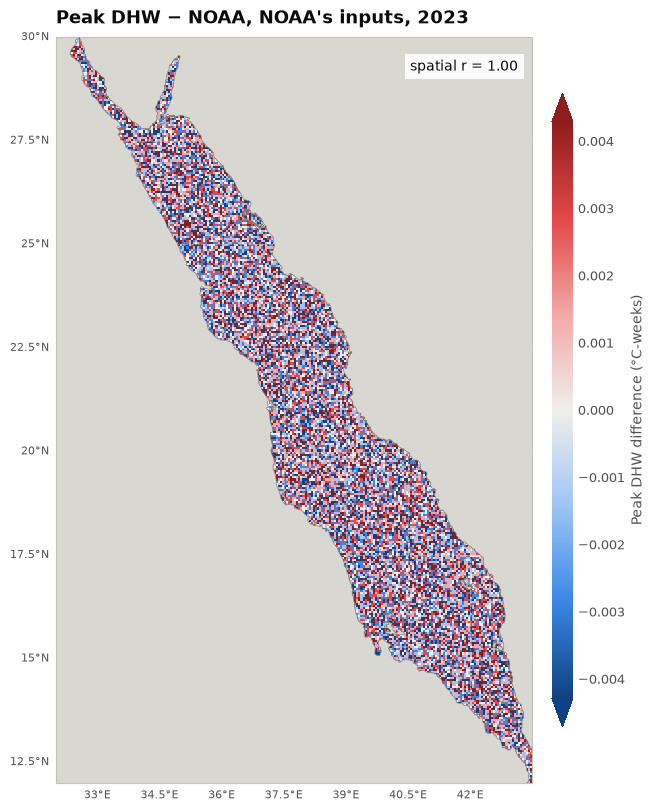

In [12]:
fig = visualise.plot_dhw_difference(
    result_same["diff"], result_same["r_spatial"],
    title=f"Peak DHW − NOAA, NOAA's inputs, {YEAR}",
)
plt.show()

## Notes
- The correlations test whether the method is right, meaning it puts heat stress
  in the same places at the same times as NOAA. The bias reflects the input
  differences described at the top.
- Large local differences near the coast are expected, since both SST products
  are least reliable there.